# 3. Modélisation

**Entrée :** `data/batiments_cible.csv` (notebook 2).

### Import des modules 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

In [2]:
df = pd.read_csv("data/batiments_cible.csv")
cible = "SiteEnergyUse(kBtu)"
print(df.shape)

(1481, 21)


### Feature Engineering

A réaliser : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

En règle générale : On utilise la méthode .apply() de Pandas pour créer une nouvelle colonne à partir d'une colonne existante. N'hésitez pas à regarder les exemples dans les chapitres de cours donnés en ressource

#### 1. Période de construction

L'année exacte compte moins que l'époque de construction (les normes d'isolation changent avec le temps). Je découpe en 4 périodes qui ont chacune assez de bâtiments.

In [3]:
def periode(annee):
    if annee < 1950:
        return "avant 1950"
    elif annee < 1980:
        return "1950-1979"
    elif annee < 2000:
        return "1980-1999"
    else:
        return "2000 et après"

df["Periode"] = df["YearBuilt"].apply(periode)
df["Periode"].value_counts()

Periode
1950-1979        494
avant 1950       475
1980-1999        288
2000 et après    224
Name: count, dtype: int64

#### 2. Utilise du gaz / de la vapeur

Les quantités de gaz et de vapeur font partie de la consommation totale, donc les garder reviendrait à donner une partie de la réponse au modèle (fuite de données). Par contre, savoir si le bâtiment est raccordé au gaz ou à la vapeur, ça se sait sans compteur. Je garde donc juste 1 (oui) ou 0 (non).

In [4]:
# 1 = oui, 0 = non
df["UtiliseGaz"] = df["NaturalGas(kBtu)"].apply(lambda x: 1 if x > 0 else 0)
df["UtiliseVapeur"] = df["SteamUse(kBtu)"].apply(lambda x: 1 if x > 0 else 0)

print("part qui utilise du gaz :", round(df["UtiliseGaz"].mean(), 2))
print("part qui utilise de la vapeur :", round(df["UtiliseVapeur"].mean(), 2))

part qui utilise du gaz : 0.71
part qui utilise de la vapeur : 0.07


#### 3. Part de la surface en parking

Un parking consomme peu. À surface égale, un bâtiment avec beaucoup de parking devrait consommer moins.

In [5]:
df["PartParking"] = df["PropertyGFAParking"] / df["PropertyGFATotal"]
df["PartParking"].describe()

count    1481.000000
mean        0.066472
std         0.145105
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         0.895023
Name: PartParking, dtype: float64

#### 4. Nombre d'usages

Je compte combien d'usages sont renseignés (1, 2 ou 3), pour voir si les bâtiments multi-usages consomment différemment.

In [6]:
df["NbUsages"] = 1 + df["SecondLargestPropertyUseType"].notna().astype(int) + df["ThirdLargestPropertyUseType"].notna().astype(int)
df["NbUsages"].value_counts()

NbUsages
1    676
2    478
3    327
Name: count, dtype: int64

#### 5. Colonnes retirées

Je retire ensuite :
- `YearBuilt`, remplacée par `Periode` ;
- les colonnes d'énergie brutes (fuite de données), remplacées par `UtiliseGaz` et `UtiliseVapeur` ;
- `ENERGYSTARScore`, qui manque pour 35 % des bâtiments et qui est calculé à partir de la consommation. Je le teste quand même à la fin du notebook.

In [7]:
colonnes_a_retirer = [
    "YearBuilt",
    "Electricity(kWh)",
    "Electricity(kBtu)",
    "NaturalGas(therms)",
    "NaturalGas(kBtu)",
    "SteamUse(kBtu)",
    "ENERGYSTARScore",
]
df = df.drop(columns=colonnes_a_retirer)
print(df.shape)
df.head()

(1481, 19)


,PrimaryPropertyType,Neighborhood,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUse(kBtu),Periode,UtiliseGaz,UtiliseVapeur,PartParking,NbUsages
0,Hotel,DOWNTOWN,1.0,12,88434,0,88434,Hotel,88434.0,NaN,0.0,NaN,0.0,7226362.5,avant 1950,1,1,0.000000,1
1,Hotel,DOWNTOWN,1.0,11,103566,15064,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,8387933.0,1980-1999,1,0,0.145453,3
2,Hotel,DOWNTOWN,1.0,41,956110,196718,759392,Hotel,756493.0,NaN,0.0,NaN,0.0,72587024.0,1950-1979,1,1,0.205748,1
3,Hotel,DOWNTOWN,1.0,10,61320,0,61320,Hotel,61320.0,NaN,0.0,NaN,0.0,6794584.0,avant 1950,1,1,0.000000,1
4,Hotel,DOWNTOWN,1.0,18,175580,62000,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,14172606.0,1980-1999,1,0,0.353115,3


### Préparation des features pour la modélisation

A réaliser :
* Si ce n'est pas déjà fait, supprimer toutes les colonnes peu pertinentes pour la modélisation.
* Tracer la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers, mettez en place une démarche pour les supprimer.
* Débarrassez-vous des features redondantes en utilisant une matrice de corrélation de Pearson. Pour cela, utiisez la méthode corr() de Pandas, couplé d'un graphique Heatmap de la librairie Seaborn 
* Réalisez différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparez votre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).
* Si vous avez des features catégorielles, il faut les encoder pour que votre modèle fonctionne. Les deux méthodes d'encodage à connaitre sont le OneHotEncoder et le LabelEncoder

#### 1. Distribution de la cible

La distribution brute est déjà dans le notebook 2. Elle est très étalée vers la droite à cause de quelques très gros bâtiments, donc je passe la cible en log10 pour qu'ils n'écrasent pas tout le reste.

asymétrie brute : 10.77
asymétrie en log10 : 0.36


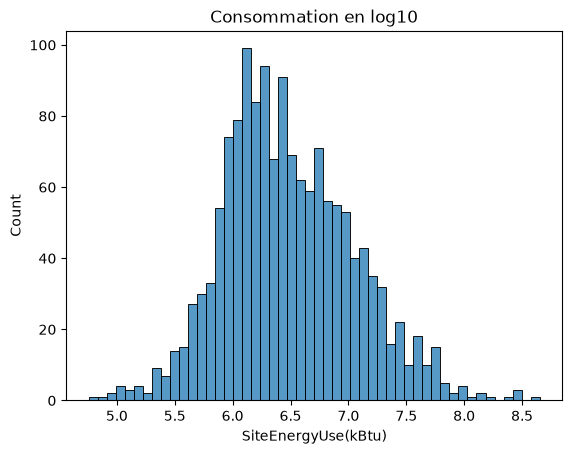

In [8]:
# cible en log10 (6 = 1 million de kBtu)
y = np.log10(df[cible])

print("asymétrie brute :", round(df[cible].skew(), 2))
print("asymétrie en log10 :", round(y.skew(), 2))

sns.histplot(y, bins=50)
plt.title("Consommation en log10")
plt.show()

Pour les outliers : en log10, il n'y a plus que 11 bâtiments en dehors des moustaches. Ce sont surtout des entrepôts et des garde-meubles qui consomment très peu. Ça me paraît normal pour ce type de bâtiment, donc je les garde.

#### 2. Matrice de corrélation

Si deux colonnes sont très corrélées (au-dessus de 0,9), elles disent presque la même chose et on peut en enlever une.

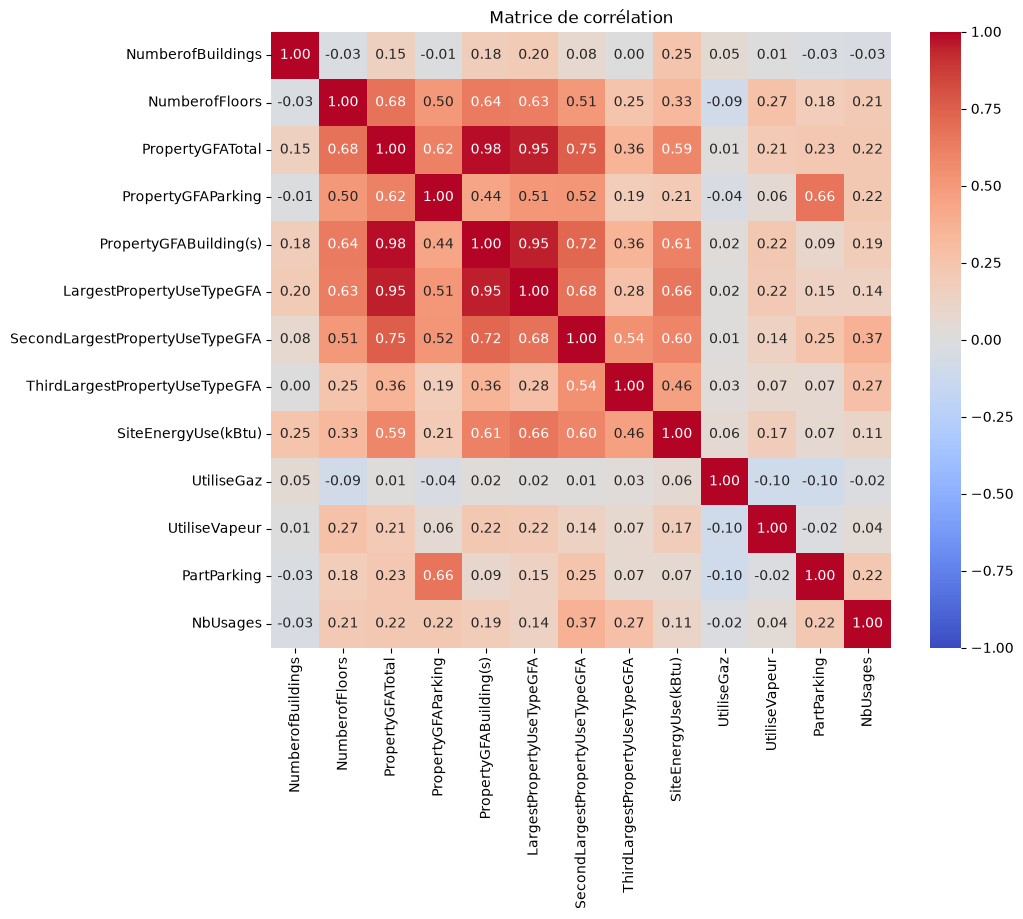

In [9]:
# corrélation de Pearson entre les colonnes numériques (cible comprise)
corr = df.select_dtypes("number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.show()

`PropertyGFATotal`, `PropertyGFABuilding(s)` et `LargestPropertyUseTypeGFA` sont corrélées entre 0,95 et 0,98. C'est logique, c'est quasiment la même surface comptée de trois façons. Le reste est en dessous de 0,8 (par exemple 0,68 entre le nombre d'étages et la surface totale).

Je garde `PropertyGFATotal`, la plus simple à expliquer (et c'est celle que j'ai utilisée pour calculer `PartParking`).

In [10]:
df = df.drop(columns=["PropertyGFABuilding(s)", "LargestPropertyUseTypeGFA"])
print(df.shape)

(1481, 17)


#### 3. Lien entre les features et la cible

Le boxplot par type de bâtiment est déjà fait dans le notebook 2, je regarde ici la surface, la période de construction et la vapeur.

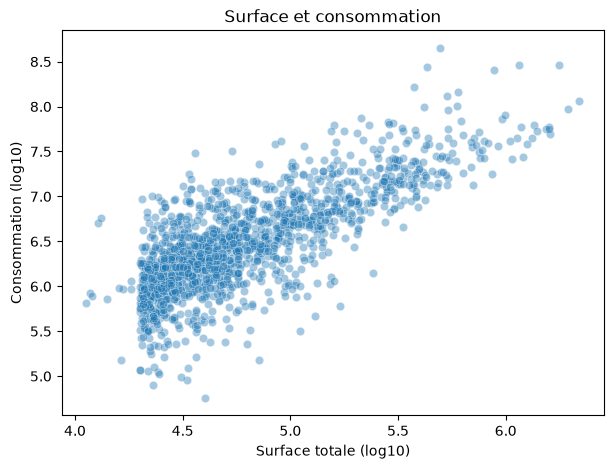

corrélation : 0.77


In [11]:
# surface et consommation en log10, sinon les très grands bâtiments écrasent le graphique
plt.figure(figsize=(7, 5))
sns.scatterplot(x=np.log10(df["PropertyGFATotal"]), y=y, alpha=0.4)
plt.xlabel("Surface totale (log10)")
plt.ylabel("Consommation (log10)")
plt.title("Surface et consommation")
plt.show()

print("corrélation :", round(np.corrcoef(np.log10(df["PropertyGFATotal"]), y)[0, 1], 2))

Les points sont presque alignés : plus le bâtiment est grand, plus il consomme. La surface devrait être la variable la plus utile pour le modèle.

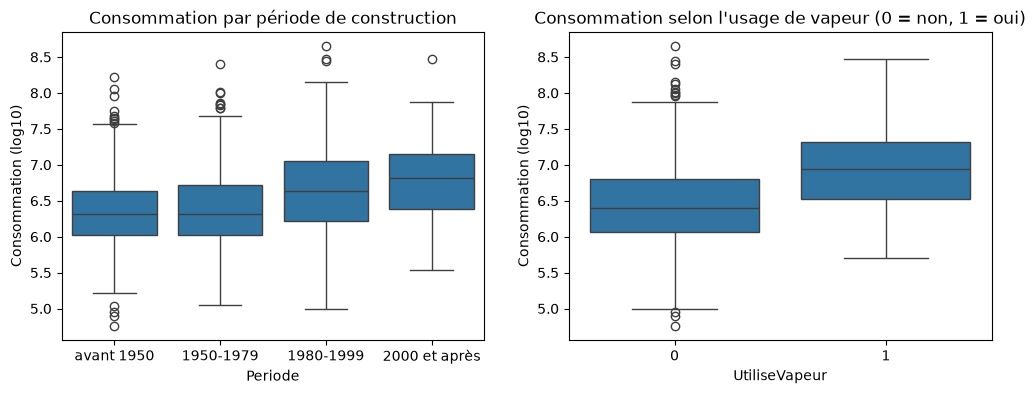

In [12]:
ordre = ["avant 1950", "1950-1979", "1980-1999", "2000 et après"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["Periode"], y=y, order=ordre, ax=axes[0])
axes[0].set_title("Consommation par période de construction")
axes[0].set_ylabel("Consommation (log10)")

sns.boxplot(x=df["UtiliseVapeur"], y=y, ax=axes[1])
axes[1].set_title("Consommation selon l'usage de vapeur (0 = non, 1 = oui)")
axes[1].set_ylabel("Consommation (log10)")
plt.show()

Pour la période, c'est l'inverse de ce que j'attendais : les bâtiments récents consomment plus (médiane autour de 6,3 avant 1980 et de 6,8 après 2000). Je pense que ce n'est pas un problème d'isolation, mais plutôt que les bâtiments récents sont plus grands.

Pour la vapeur, les bâtiments raccordés consomment environ 3,5 fois plus (médiane 6,9 contre 6,4). Ce sont surtout les gros bâtiments du centre-ville reliés au réseau de chaleur.

Pour le gaz, l'écart est très faible (6,4 dans les deux cas), donc je n'ai pas fait de graphique.

#### 4. Séparation X / y

Avant de séparer, je corrige deux choses dans les colonnes texte. Les quartiers sont parfois en majuscules et parfois non (`NORTH` et `North`), donc je mets tout en majuscules. Et quand il n'y a pas de 2e ou 3e usage, je mets « Aucun » à la place de la case vide.

In [13]:
df["Neighborhood"] = df["Neighborhood"].str.upper().replace("DELRIDGE NEIGHBORHOODS", "DELRIDGE")
print("quartiers :", df["Neighborhood"].nunique())

usages = ["LargestPropertyUseType", "SecondLargestPropertyUseType", "ThirdLargestPropertyUseType"]
df[usages] = df[usages].fillna("Aucun")

quartiers : 13


Les surfaces sont très étalées elles aussi, donc je les passe en log10 comme la cible. J'ajoute 1 avant le log parce que les parkings et les 2e/3e usages peuvent valoir 0 m².

In [14]:
surfaces = ["PropertyGFATotal", "PropertyGFAParking", "SecondLargestPropertyUseTypeGFA", "ThirdLargestPropertyUseTypeGFA"]
for col in surfaces:
    df[col] = np.log10(df[col] + 1)

df[surfaces].describe().round(2)

,PropertyGFATotal,PropertyGFAParking,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA
count,1481.00,1481.00,1481.00,1481.00
mean,4.79,0.98,2.07,0.79
std,0.42,1.89,2.14,1.56
min,4.05,0.00,0.00,0.00
25%,4.46,0.00,0.00,0.00
50%,4.68,0.00,0.00,0.00
75%,5.02,0.00,4.13,0.00
max,6.34,5.71,5.81,5.66


In [15]:
# X = les infos du bâtiment, y = la conso en log10 (créée plus haut)
X = df.drop(columns=[cible])

# 80 % pour entraîner, 20 % gardés de côté pour le test final
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train :", X_train.shape, " test :", X_test.shape)

train : (1184, 16)  test : (297, 16)


#### 5. Encodage et mise à l'échelle

Les colonnes texte passent dans un `OneHotEncoder` (une colonne 0/1 par catégorie). Avec `handle_unknown="ignore"`, on évite une erreur si une catégorie rare n'apparaît que dans le test.

Je n'ai pas pris le `LabelEncoder` parce qu'il transforme les catégories en 1, 2, 3… et le modèle penserait qu'il y a un ordre entre les quartiers ou les usages.

Les colonnes numériques passent dans un `StandardScaler` pour être à la même échelle, ce qui est nécessaire pour le SVR et la régression linéaire.

Je mets ce préprocesseur dans un `Pipeline` avec chaque modèle. Comme ça, l'encodage et le scaling sont calculés seulement sur la partie entraînement à chaque tour de la validation croisée. Sinon, une partie de l'info du test passerait dans l'entraînement.

In [16]:
colonnes_texte = X.select_dtypes(exclude="number").columns.tolist()
colonnes_nombres = X.select_dtypes("number").columns.tolist()
print("texte :", colonnes_texte)
print("nombres :", colonnes_nombres)

preprocesseur = ColumnTransformer([
    ("texte", OneHotEncoder(handle_unknown="ignore"), colonnes_texte),
    ("nombres", StandardScaler(), colonnes_nombres),
])

# vérification : combien de colonnes après encodage ?
print(preprocesseur.fit_transform(X_train).shape)

texte : ['PrimaryPropertyType', 'Neighborhood', 'LargestPropertyUseType', 'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType', 'Periode']
nombres : ['NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseTypeGFA', 'UtiliseGaz', 'UtiliseVapeur', 'PartParking', 'NbUsages']
(1184, 180)


### Comparaison de différents modèles supervisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

In [17]:
modeles = {
    "Dummy": DummyRegressor(),
    "Régression linéaire": LinearRegression(),
    "SVR": SVR(),
    "RandomForest": RandomForestRegressor(random_state=42),
}

# sklearn renvoie les erreurs en négatif (plus c'est grand, mieux c'est), on remettra le signe
metriques = {"R2": "r2", "MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}

resultats = []
for nom, modele in modeles.items():
    pipe = Pipeline([("preprocesseur", preprocesseur), ("modele", modele)])
    # validation croisée en 5 plis, sur le jeu d'entraînement seulement
    scores = cross_validate(pipe, X_train, y_train, cv=5, scoring=metriques, return_train_score=True)
    resultats.append({
        "modèle": nom,
        "R2 train": scores["train_R2"].mean(),
        "R2 validation": scores["test_R2"].mean(),
        "MAE train": -scores["train_MAE"].mean(),
        "MAE validation": -scores["test_MAE"].mean(),
        "RMSE train": -scores["train_RMSE"].mean(),
        "RMSE validation": -scores["test_RMSE"].mean(),
        "temps (s)": scores["fit_time"].mean(),
    })

pd.DataFrame(resultats).round(3)

,modèle,R2 train,R2 validation,MAE train,MAE validation,RMSE train,RMSE validation,temps (s)
0,Dummy,0.000,-0.005,0.443,0.444,0.556,0.556,0.006
1,Régression linéaire,0.811,0.708,0.182,0.227,0.242,0.299,0.013
2,SVR,0.883,0.730,0.139,0.217,0.191,0.287,0.037
3,RandomForest,0.960,0.714,0.082,0.221,0.111,0.296,1.096


Les 3 modèles font beaucoup mieux que le Dummy (R² proche de 0), donc ils apprennent bien quelque chose.

Le SVR est le meilleur en validation (R² = 0,73 et MAE = 0,22). Une MAE de 0,22 en log10 veut dire qu'on se trompe en général d'un facteur 1,7 environ sur la consommation.

Le RandomForest sur-apprend : 0,96 en train mais 0,71 en validation. La régression linéaire est juste derrière avec 0,71.

Je garde donc le SVR pour l'optimisation.

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

#### GridSearch sur le SVR

Les 3 hyperparamètres testés :
- `C` : plus il est grand, plus le modèle colle aux données d'entraînement (risque de sur-apprentissage) ;
- `gamma` : plus il est grand, plus la courbe peut être tordue ;
- `epsilon` : l'erreur qu'on tolère sans pénalité.

In [18]:
pipe_svr = Pipeline([("preprocesseur", preprocesseur), ("modele", SVR())])

# "modele__" = le paramètre appartient à l'étape "modele" du pipeline
grille = {
    "modele__C": [1, 10, 100],
    "modele__gamma": ["scale", 0.01, 0.001],
    "modele__epsilon": [0.1, 0.2],
}

grid = GridSearchCV(pipe_svr, grille, cv=5, scoring="r2", return_train_score=True)
grid.fit(X_train, y_train)

print("meilleurs paramètres :", grid.best_params_)
print("R2 validation :", round(grid.best_score_, 3))
print("R2 train :", round(grid.cv_results_["mean_train_score"][grid.best_index_], 3))

meilleurs paramètres : {'modele__C': 100, 'modele__epsilon': 0.2, 'modele__gamma': 0.001}
R2 validation : 0.739
R2 train : 0.809


Le GridSearch améliore un peu le score (0,73 → 0,74) et l'écart entre train et validation diminue (0,81 contre 0,74).

#### Évaluation finale sur le jeu de test

Je n'ai pas touché au jeu de test jusqu'ici, c'est lui qui donne la vraie performance du modèle.

In [19]:
y_pred = grid.predict(X_test)

print("R2 test :", round(r2_score(y_test, y_pred), 3))
print("MAE test :", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE test :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

R2 test : 0.781
MAE test : 0.215
RMSE test : 0.283


R² = 0,78 sur le test, proche de la validation (0,74), donc le modèle marche aussi sur des bâtiments qu'il n'a jamais vus. Il explique environ 78 % des variations de consommation (en log) avec seulement des informations connues sans compteur.

#### Variables les plus importantes : permutation importance

Le SVR n'a pas de `feature_importances_` (c'est pour les modèles à arbres), donc j'utilise la permutation importance. On mélange une colonne à la fois dans le jeu de test et on regarde de combien le R² baisse. Comme je le calcule sur le pipeline complet, on obtient l'importance des 16 colonnes de départ et pas des colonnes après encodage.

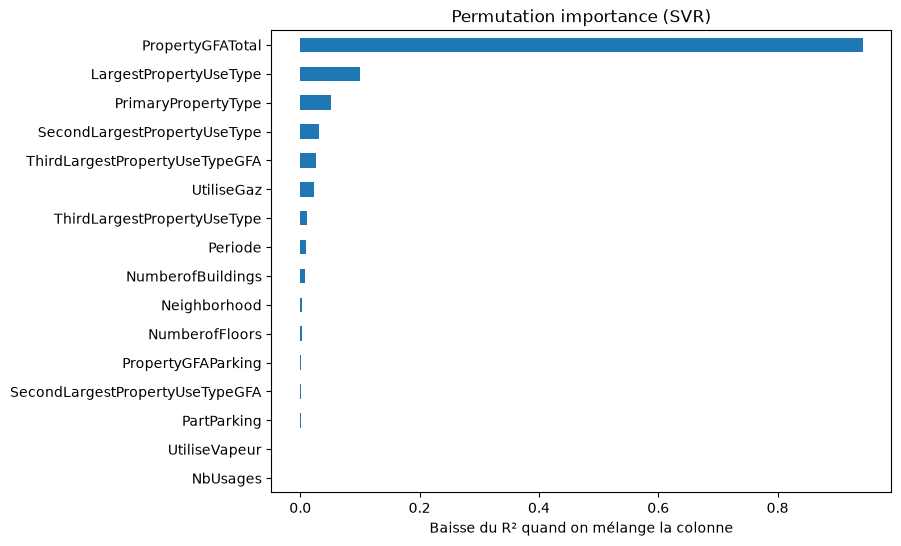

PropertyGFATotal                   0.944
LargestPropertyUseType             0.101
PrimaryPropertyType                0.052
SecondLargestPropertyUseType       0.031
ThirdLargestPropertyUseTypeGFA     0.026
UtiliseGaz                         0.023
ThirdLargestPropertyUseType        0.012
Periode                            0.010
NumberofBuildings                  0.008
Neighborhood                       0.003
NumberofFloors                     0.003
PropertyGFAParking                 0.002
SecondLargestPropertyUseTypeGFA    0.002
PartParking                        0.001
UtiliseVapeur                      0.000
NbUsages                          -0.001
dtype: float64

In [20]:
# 10 mélanges par colonne pour lisser le hasard
perm = permutation_importance(grid, X_test, y_test, n_repeats=10, scoring="r2", random_state=42)

importances = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 6))
importances.plot(kind="barh")
plt.xlabel("Baisse du R² quand on mélange la colonne")
plt.title("Permutation importance (SVR)")
plt.show()

importances.sort_values(ascending=False).round(3)

La surface totale est de loin la plus importante : quand on la mélange, le R² baisse d'environ 0,94 et le modèle ne sait presque plus rien prédire. Ensuite viennent les usages (environ 0,10 pour l'usage principal et 0,05 pour le type de bâtiment) : à surface égale, un hôpital et un entrepôt ne consomment pas pareil. Le gaz compte un peu (0,02), la période très peu (0,01).

La vapeur ne compte presque pas, alors que sur le boxplot les bâtiments raccordés consommaient 3,5 fois plus. Comme pour la période, c'est en fait la surface qui expliquait cet écart.

En résumé, pour prédire la consommation d'un bâtiment non résidentiel à Seattle, il faut surtout connaître sa surface, puis son usage.

#### Test : le modèle avec `ENERGYSTARScore`

J'avais retiré ce score au feature engineering. Je le remets ici pour voir ce qu'il apporte, avec le même SVR. Pour les 35 % de cases vides, je mets la médiane calculée sur le jeu d'entraînement.

In [21]:
# on relit le score dans le fichier (même ordre de lignes que df)
score_es = pd.read_csv("data/batiments_cible.csv")["ENERGYSTARScore"]

X_train_es = X_train.copy()
X_test_es = X_test.copy()
X_train_es["ENERGYSTARScore"] = score_es[X_train.index]
X_test_es["ENERGYSTARScore"] = score_es[X_test.index]

# médiane calculée sur le train seulement
mediane = X_train_es["ENERGYSTARScore"].median()
X_train_es["ENERGYSTARScore"] = X_train_es["ENERGYSTARScore"].fillna(mediane)
X_test_es["ENERGYSTARScore"] = X_test_es["ENERGYSTARScore"].fillna(mediane)

In [22]:
preprocesseur_es = ColumnTransformer([
    ("texte", OneHotEncoder(handle_unknown="ignore"), colonnes_texte),
    ("nombres", StandardScaler(), colonnes_nombres + ["ENERGYSTARScore"]),
])

# même SVR que le GridSearch
pipe_es = Pipeline([("preprocesseur", preprocesseur_es), ("modele", SVR())])
pipe_es.set_params(**grid.best_params_)

scores_es = cross_validate(pipe_es, X_train_es, y_train, cv=5, scoring="r2")
pipe_es.fit(X_train_es, y_train)

print("sans le score : R2 validation", round(grid.best_score_, 3), "| R2 test", round(r2_score(y_test, y_pred), 3))
print("avec le score : R2 validation", round(scores_es["test_score"].mean(), 3), "| R2 test", round(r2_score(y_test, pipe_es.predict(X_test_es)), 3))

sans le score : R2 validation 0.739 | R2 test 0.781
avec le score : R2 validation 0.783 | R2 test 0.838


Avec le score, le modèle est meilleur (R² de validation de 0,74 à 0,78, et de 0,78 à 0,84 sur le test).

Je ne le garde quand même pas dans le modèle final. Le score ENERGY STAR est calculé à partir de la consommation mesurée, donc c'est en partie la réponse (fuite de données). Et pour un bâtiment qui n'a jamais été mesuré, la ville n'a pas ce score, donc le modèle ne servirait à rien. En plus, il manque déjà pour 35 % des bâtiments.

Le modèle final reste donc le SVR sans le score, avec un R² de 0,78 sur le test.